In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import torch
from torch_geometric.utils import dense_to_sparse
import matplotlib.pyplot as plt
import networkx as nx

# 1. 读取数据
data = pd.read_feather('/home/user96/label_data1/can_trade_amt1.fea')
data.set_index('index', inplace=True)
data.fillna(0, inplace=True)



In [2]:
# 2. 获取节点 ID
node_ids = data.columns.tolist()  # e.g., ['000001', '000002', ...]

In [3]:
# 3. 标准化特征（按列，也就是每个股票的时间序列）
scaler = StandardScaler()
data_std = pd.DataFrame(scaler.fit_transform(data), index=data.index, columns=node_ids)

In [4]:
# 4. 构建相关系数矩阵
corr_matrix = data_std.corr()

In [5]:
# 5. 设置阈值生成邻接矩阵
threshold = 0.2
adj_matrix = (corr_matrix > threshold).astype(int)
np.fill_diagonal(adj_matrix.values, 0)  # 去掉自环

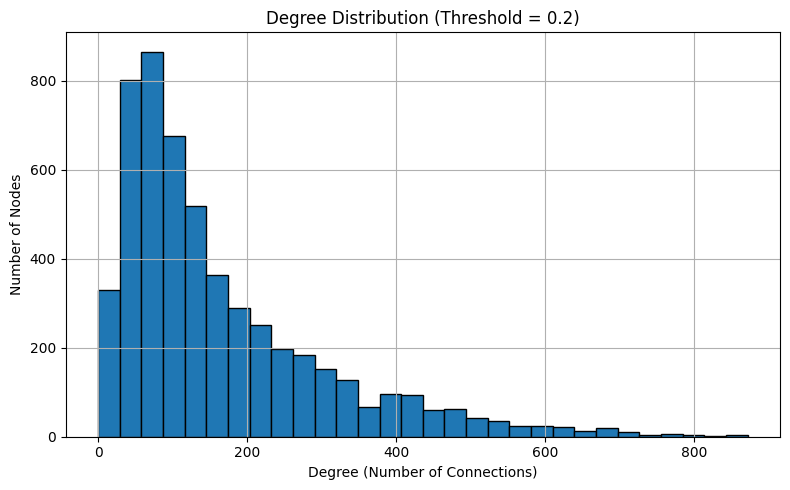

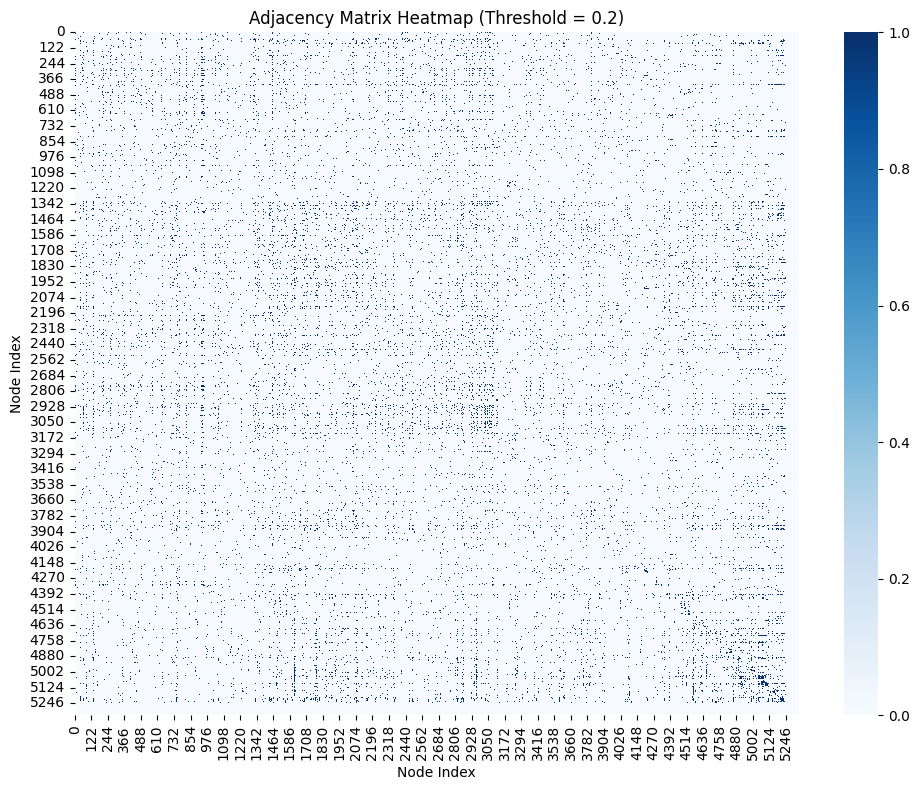

In [6]:
import seaborn as sns
# 统计每个节点的度（连边数）
degree = adj_matrix.sum(axis=1)

# 可视化：度分布直方图
plt.figure(figsize=(8, 5))
plt.hist(degree, bins=30, edgecolor='k')
plt.xlabel("Degree (Number of Connections)")
plt.ylabel("Number of Nodes")
plt.title(f"Degree Distribution (Threshold = {threshold})")
plt.grid(True)
plt.tight_layout()
plt.show()

# 可视化：邻接矩阵热力图
plt.figure(figsize=(10, 8))
sns.heatmap(adj_matrix.values, cmap='Blues')
plt.title(f"Adjacency Matrix Heatmap (Threshold = {threshold})")
plt.xlabel("Node Index")
plt.ylabel("Node Index")
plt.tight_layout()
plt.show()


In [7]:
# 7. 邻接稀疏矩阵 edge_index
edge_index = dense_to_sparse(torch.tensor(adj_matrix.values))[0]  # shape: [2, num_edges]

In [8]:
edge_index.shape

torch.Size([2, 879584])

In [9]:
# 8. 保存或输出数据结构
graph_data = {
    "edge_index": edge_index,                 # 边列表 (用于GCN)
    "node_ids": node_ids                      # 节点ID，顺序与X和adj一致
}

In [10]:
graph_data

{'edge_index': tensor([[   0,    0,    0,  ..., 5247, 5247, 5247],
         [   1,   44,   48,  ..., 5222, 5245, 5246]]),
 'node_ids': ['000001',
  '000002',
  '000004',
  '000005',
  '000006',
  '000008',
  '000009',
  '000010',
  '000011',
  '000012',
  '000014',
  '000016',
  '000019',
  '000020',
  '000021',
  '000023',
  '000025',
  '000026',
  '000027',
  '000028',
  '000029',
  '000030',
  '000031',
  '000032',
  '000034',
  '000035',
  '000036',
  '000037',
  '000038',
  '000039',
  '000040',
  '000042',
  '000045',
  '000046',
  '000048',
  '000049',
  '000050',
  '000055',
  '000056',
  '000058',
  '000059',
  '000060',
  '000061',
  '000062',
  '000063',
  '000065',
  '000066',
  '000068',
  '000069',
  '000070',
  '000078',
  '000088',
  '000089',
  '000090',
  '000096',
  '000099',
  '000100',
  '000150',
  '000151',
  '000153',
  '000155',
  '000156',
  '000157',
  '000158',
  '000159',
  '000166',
  '000301',
  '000333',
  '000338',
  '000400',
  '000401',
  '000402',
  

In [11]:
import pickle

with open("graph_input.pkl", "wb") as f:
    pickle.dump(graph_data, f)